<a href="https://colab.research.google.com/github/palakmirok/radar-detection-performance/blob/main/CFAR_Monte_Carlo_Comparison_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Measured Pfa (CA, OS): (np.float64(0.00096), np.float64(0.000976))


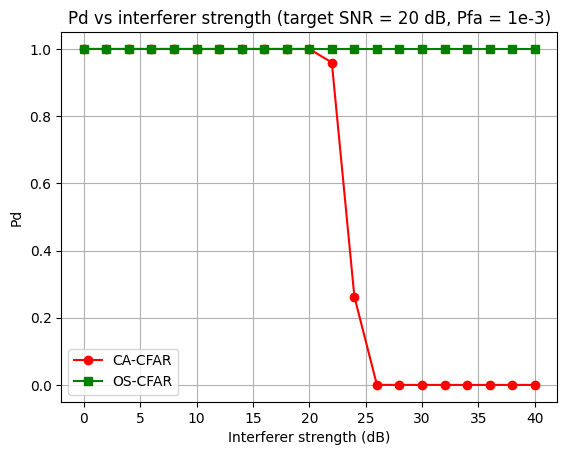

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

rng = np.random.default_rng(0)

train, guard, pfa = 10, 2, 1e-3
n = 2*train                       # total training cells
k = int(0.75*n)                   # OS-CFAR rank

alpha_ca = n*(pfa**(-1/n) - 1)

def f(T):
    i = np.arange(n-k+1, n+1)
    return np.prod(i/(i+T)) - pfa
alpha_os = brentq(f, 0.1, 1000)

L = 2*(train+guard) + 1           # window ki length
cut = train + guard               # cell under test ki position

def run(snr_db=None, inr_db=None, trials=20000):
    x = (rng.standard_normal((trials, L)) +
         1j*rng.standard_normal((trials, L))) / np.sqrt(2)
    if snr_db is not None:
        x[:, cut] += np.sqrt(10**(snr_db/10))              # asli target
    if inr_db is not None:
        x[:, cut+guard+3] += np.sqrt(10**(inr_db/10))      # bagal ka strong target
    p = np.abs(x)**2
    cells = np.concatenate([p[:, :train], p[:, -train:]], axis=1)
    c = p[:, cut]
    det_ca = c > alpha_ca * cells.mean(axis=1)
    det_os = c > alpha_os * np.sort(cells, axis=1)[:, k-1]
    return det_ca.mean(), det_os.mean()

# Check 1: sirf noise, Pfa 0.001 ke paas aana chahiye
print("Measured Pfa (CA, OS):", run(snr_db=None, trials=500000))

# Check 2: target 20 dB, interferer 0 se 40 dB tak
inrs = np.arange(0, 41, 2)
pd_ca, pd_os = [], []
for inr in inrs:
    a, b = run(snr_db=20, inr_db=inr)
    pd_ca.append(a)
    pd_os.append(b)

plt.plot(inrs, pd_ca, 'r-o', label='CA-CFAR')
plt.plot(inrs, pd_os, 'g-s', label='OS-CFAR')
plt.xlabel('Interferer strength (dB)')
plt.ylabel('Pd')
plt.title('Pd vs interferer strength (target SNR = 20 dB, Pfa = 1e-3)')
plt.grid(True)
plt.legend()
plt.show()